# Agency Revenue Intelligence — Exploratory Data Analysis

## Project Objective

Analyze monthly agency revenue, client growth, and revenue composition to understand historical business performance and prepare for time-series forecasting.


In [ ]:

## 1. Business Problem

An agency generates revenue through two primary streams:

- Retainer Revenue: Recurring revenue from ongoing client contracts.
- Project Fee Revenue: Revenue generated from individual client projects.

The objective of this analysis is to understand historical revenue performance, identify growth patterns, investigate revenue composition, and prepare the dataset for monthly revenue forecasting.

### Key Business Questions

1. How has recognized agency revenue evolved over time?
2. What proportion of revenue comes from retainers versus project fees?
3. Is revenue growth driven by an increase in active clients?
4. Are there unusual revenue fluctuations or outliers?
5. What historical patterns should inform forecasting models?

### Forecasting Objective

Predict monthly recognized agency revenue using historical business performance and compare statistical and machine learning forecasting approaches.


In [5]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:

# ============================================================
# 2. LIBRARY IMPORTS AND CONFIGURATION
# ============================================================

# Data manipulation

import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and file handling
from pathlib import Path

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Visualization configuration
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Project paths
PROJECT_DIR = Path.cwd()

DATA_DIR = (
    PROJECT_DIR.parent / "data" / "processed_candidate"
)

print("Libraries imported successfully.")
print("Current working directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())


Libraries imported successfully.
Current working directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence/notebooks
Data directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence/data/processed_candidate
Data directory exists: True


In [7]:
# ============================================================
# 3. LOAD AND INSPECT AGENCY MONTHLY DATA
# ============================================================

agency_df = pd.read_parquet(
    DATA_DIR / "agency_monthly.parquet"
)

# Convert month column to datetime
agency_df["month"] = pd.to_datetime(agency_df["month"])

# Sort chronologically
agency_df = (
    agency_df
    .sort_values("month")
    .reset_index(drop=True)
)

# Display first five records
display(agency_df.head())

# Dataset dimensions
print("Dataset shape:", agency_df.shape)

# Column information
print("\nDataset information:")
agency_df.info()

# Check missing values
print("\nMissing values:")
display(agency_df.isnull().sum())

,month,recognized_agency_revenue,retainer_revenue_inr,project_fee_revenue_inr,active_clients,new_clients,synthetic_data
0,2023-11-30,0.00,0.00,0.00,0,0,True
1,2023-12-31,"255,422.30","255,422.30",0.00,2,2,True
2,2024-01-31,"415,750.47","323,900.97","91,849.50",3,1,True
3,2024-02-29,"725,575.53","610,881.74","114,693.79",6,3,True
4,2024-03-31,"822,962.38","711,691.26","111,271.12",7,1,True


Dataset shape: (36, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   month                      36 non-null     datetime64[ns]
 1   recognized_agency_revenue  36 non-null     float64       
 2   retainer_revenue_inr       36 non-null     float64       
 3   project_fee_revenue_inr    36 non-null     float64       
 4   active_clients             36 non-null     int64         
 5   new_clients                36 non-null     int64         
 6   synthetic_data             36 non-null     bool          
dtypes: bool(1), datetime64[ns](1), float64(3), int64(2)
memory usage: 1.8 KB

Missing values:


month                        0
recognized_agency_revenue    0
retainer_revenue_inr         0
project_fee_revenue_inr      0
active_clients               0
new_clients                  0
synthetic_data               0
dtype: int64

In [8]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS AND BUSINESS-RULE CHECKS
# ============================================================

# 1. Summary statistics
print("REVENUE AND CLIENT METRICS — SUMMARY")
display(
    agency_df[
        [
            "recognized_agency_revenue",
            "retainer_revenue_inr",
            "project_fee_revenue_inr",
            "active_clients",
            "new_clients",
        ]
    ].describe().round(2)
)

# 2. Verify revenue reconciliation
agency_df["revenue_difference"] = (
    agency_df["recognized_agency_revenue"]
    - agency_df["retainer_revenue_inr"]
    - agency_df["project_fee_revenue_inr"]
)

print("\nREVENUE RECONCILIATION")
print(
    "Maximum absolute difference:",
    agency_df["revenue_difference"].abs().max()
)

print(
    "All revenue components reconcile:",
    np.allclose(
        agency_df["recognized_agency_revenue"],
        agency_df["retainer_revenue_inr"]
        + agency_df["project_fee_revenue_inr"],
        atol=0.01,
    )
)

# 3. Verify monthly continuity
expected_months = pd.date_range(
    start=agency_df["month"].min(),
    end=agency_df["month"].max(),
    freq="ME",
)

print("\nDATE CONTINUITY")
print("Expected months:", len(expected_months))
print("Actual months:", agency_df["month"].nunique())
print(
    "All months present:",
    agency_df["month"].reset_index(drop=True).equals(
        pd.Series(expected_months, name="month")
    )
)

# 4. Business activity overview
print("\nBUSINESS ACTIVITY")
print("Total new clients:", agency_df["new_clients"].sum())
print("Latest active clients:", agency_df["active_clients"].iloc[-1])
print(
    "Months with zero revenue:",
    (agency_df["recognized_agency_revenue"] == 0).sum()
)

REVENUE AND CLIENT METRICS — SUMMARY


,recognized_agency_revenue,retainer_revenue_inr,project_fee_revenue_inr,active_clients,new_clients
count,36.00,36.00,36.00,36.00,36.00
mean,"4,234,157.42","3,826,326.14","407,831.28",26.25,1.39
std,"2,450,301.50","2,224,534.86","246,607.34",14.08,1.29
min,0.00,0.00,0.00,0.00,0.00
25%,"2,051,750.11","1,782,675.21","213,991.60",14.50,0.00
50%,"4,318,964.82","3,798,186.56","407,057.70",26.00,1.00
75%,"6,482,415.63","6,018,587.32","579,728.64",39.50,2.00
max,"7,665,218.67","6,987,424.04","885,553.10",46.00,4.00



REVENUE RECONCILIATION
Maximum absolute difference: 8.149072527885437e-10
All revenue components reconcile: True

DATE CONTINUITY
Expected months: 36
Actual months: 36
All months present: True

BUSINESS ACTIVITY
Total new clients: 50
Latest active clients: 45
Months with zero revenue: 1


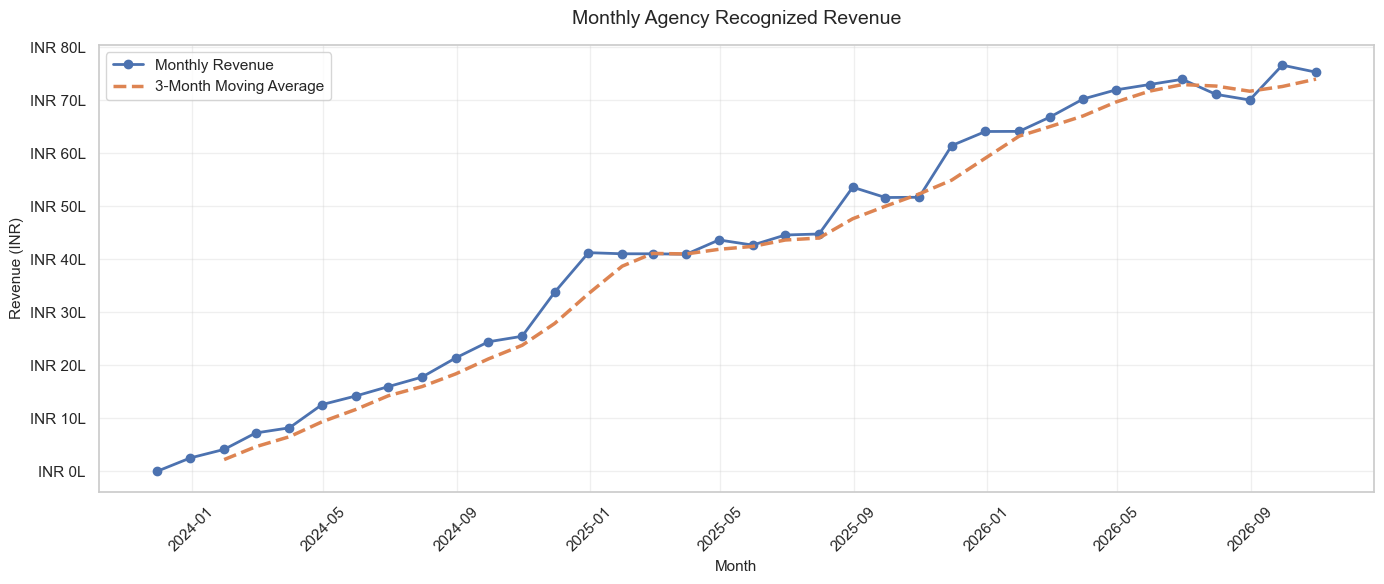

In [10]:
# ============================================================
# 5. MONTHLY AGENCY REVENUE TREND
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

# Monthly revenue
ax.plot(
    agency_df["month"],
    agency_df["recognized_agency_revenue"],
    marker="o",
    linewidth=2,
    label="Monthly Revenue",
)

# Three-month moving average
agency_df["revenue_3m_avg"] = (
    agency_df["recognized_agency_revenue"]
    .rolling(window=3)
    .mean()
)

ax.plot(
    agency_df["month"],
    agency_df["revenue_3m_avg"],
    linestyle="--",
    linewidth=2.5,
    label="3-Month Moving Average",
)

# Formatting
ax.set_title("Monthly Agency Recognized Revenue", pad=15)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (INR)")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"INR {x / 100000:.0f}L")
)

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
print("Total observations:", len(agency_df))

display(
    agency_df[
        ["month", "recognized_agency_revenue"]
    ].tail(12)
)

Total observations: 36


,month,recognized_agency_revenue
24,2025-11-30,"6,147,724.89"
25,2025-12-31,"6,413,412.79"
26,2026-01-31,"6,415,836.49"
27,2026-02-28,"6,682,153.04"
28,2026-03-31,"7,027,875.41"
29,2026-04-30,"7,198,334.48"
30,2026-05-31,"7,299,708.99"
31,2026-06-30,"7,398,294.02"
32,2026-07-31,"7,114,002.98"
33,2026-08-31,"7,008,055.60"


### Key Observations

- Agency revenue demonstrates an overall upward trend.
- Revenue growth accelerates during late 2024 and early 2025.
- A temporary period of revenue stabilization is visible around INR 40–44 lakh.
- The 3-month moving average smooths short-term fluctuations and highlights the underlying trend.
- The observed growth suggests that client acquisition and recurring retainer revenue may be important forecasting drivers.

**Forecasting implication:** The revenue series exhibits a strong trend. Forecasting models should account for this trend rather than relying only on historical averages.

Start date: 2023-11-30 00:00:00
End date: 2026-10-31 00:00:00
Total months: 36


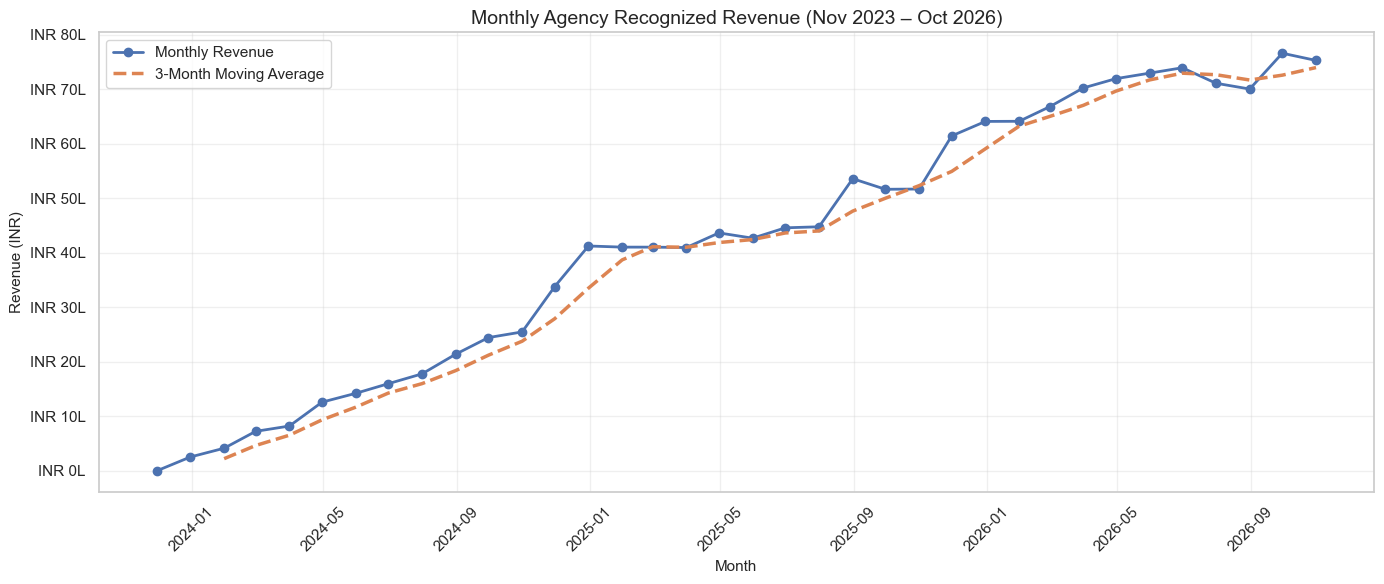

In [13]:
# Verify the complete date range
print("Start date:", agency_df["month"].min())
print("End date:", agency_df["month"].max())
print("Total months:", len(agency_df))

# Recreate the chart using all observations
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    agency_df["month"],
    agency_df["recognized_agency_revenue"],
    marker="o",
    linewidth=2,
    label="Monthly Revenue",
)

revenue_3m_avg = (
    agency_df["recognized_agency_revenue"]
    .rolling(window=3)
    .mean()
)

ax.plot(
    agency_df["month"],
    revenue_3m_avg,
    linestyle="--",
    linewidth=2.5,
    label="3-Month Moving Average",
)

ax.set_title("Monthly Agency Recognized Revenue (Nov 2023 – Oct 2026)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (INR)")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"INR {x / 100000:.0f}L")
)

ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Observations — Monthly Agency Revenue

1. **Overall growth:** Agency revenue demonstrates a strong upward trend over the 36-month observation period.
2. **Initial growth phase:** Revenue increased steadily from November 2023 through December 2024.
3. **Temporary plateau:** Revenue remained relatively stable around ₹41–45 lakh during early to mid-2025.
4. **Renewed growth:** Revenue accelerated from September 2025 and crossed ₹70 lakh by April 2026.
5. **Recent stabilization:** Revenue fluctuated around ₹70–77 lakh during the final six months, reaching approximately ₹75.32 lakh in October 2026.
6. **Moving average:** The 3-month moving average smooths short-term fluctuations and highlights the underlying upward trend.

**Forecasting implications:**

- The revenue series exhibits a strong upward trend.
- Forecasting models should account for trend and potential changes in growth rate.
- Client acquisition, active client count, and revenue composition should be investigated as potential explanatory factors.
- Annual seasonality should be tested rather than assumed, given the limited 36-month history.